Elements of workflow adapted from https://github.com/eu-cdse/notebook-samples/blob/main/openeo/NDVI_Timeseries.ipynb

In [4]:
import os
import json

experiment_name = "pacific_palisades"
experiments_dir = "experiments"
experiment_path = os.path.join(experiments_dir, experiment_name)
os.makedirs(experiment_path, exist_ok=True)

SPATIAL_EXTENT = {"west": -118.5650, "south": 34.0300, "east": -118.5000, "north": 34.0900}

TEMPORAL_EXTENT = ["2024-10-01", "2025-02-28"]
TEMPORAL_EXTENT_FIRE = ["2025-01-07", "2025-01-31"]
TEMPORAL_EXTENT_PRE_FIRE = [TEMPORAL_EXTENT[0], TEMPORAL_EXTENT_FIRE[0]]
TEMPORAL_EXTENT_POST_FIRE = [TEMPORAL_EXTENT_FIRE[1], TEMPORAL_EXTENT[1]]


coordinates = [
    [SPATIAL_EXTENT["west"], SPATIAL_EXTENT["north"]],
    [SPATIAL_EXTENT["east"], SPATIAL_EXTENT["north"]],
    [SPATIAL_EXTENT["east"], SPATIAL_EXTENT["south"]],
    [SPATIAL_EXTENT["west"], SPATIAL_EXTENT["south"]],
    [SPATIAL_EXTENT["west"], SPATIAL_EXTENT["north"]]  # Closing the polygon
]

# Construct the GeoJSON object
fields = {
    "type": "FeatureCollection",
    "features": [
        {
            "type": "Feature",
            "properties": {
                "temporal_extent": TEMPORAL_EXTENT
            },
            "geometry": {
                "type": "Polygon",
                "coordinates": [coordinates]
            }
        }
    ]
}

fields_path = os.path.join(experiment_path, "fields.json")
with open(fields_path, "w") as f:
    json.dump(fields, f, indent=4)

print(f"GeoJSON saved at: {fields_path}")

fields

GeoJSON saved at: experiments/pacific_palisades/fields.json


{'type': 'FeatureCollection',
 'features': [{'type': 'Feature',
   'properties': {'temporal_extent': ['2024-10-01', '2025-02-28']},
   'geometry': {'type': 'Polygon',
    'coordinates': [[[-118.565, 34.09],
      [-118.5, 34.09],
      [-118.5, 34.03],
      [-118.565, 34.03],
      [-118.565, 34.09]]]}}]}

In [ ]:
from utils.openeo_connection import get_openeo_connection

connection = get_openeo_connection()

ndvi_csv_path = os.path.join(experiment_path, "ndvi-results", "timeseries-smoothed.csv")
s5p_csv_path = os.path.join(experiment_path, "s5p-results", "s5p_fire.csv")

Authenticated using refresh token.


## Sentinel-2

In [3]:
s2cube = connection.load_collection(
    "SENTINEL2_L2A",
    temporal_extent = TEMPORAL_EXTENT,
    bands=["B04", "B08", "SCL"]
)

### NDVI

In [4]:
import scipy.signal
import numpy as np
import pandas as pd

# Compute NDVI
red = s2cube.band("B04")
nir = s2cube.band("B08")
ndvi = (nir - red) / (nir + red)

# Cloud mask using the SCL band
scl = s2cube.band("SCL")
mask = ~((scl == 4) | (scl == 5))

# 2D Gaussian kernel
g = scipy.signal.windows.gaussian(11, std=1.6)
kernel = np.outer(g, g)
kernel = kernel / kernel.sum()

# Morphological dilation of mask: convolution + threshold
mask = mask.apply_kernel(kernel)
mask = mask > 0.1

# Apply mask to NDVI
ndvi_masked = ndvi.mask(mask)
timeseries_masked = ndvi_masked.aggregate_spatial(geometries=fields, reducer="mean")

# Convert to Pandas & Save
timeseries_masked_df = pd.DataFrame(timeseries_masked.execute())
masked_output_csv = os.path.join(experiment_path, "timeseries_masked.csv")
timeseries_masked_df.to_csv(masked_output_csv, index=False)

print(f"Masked timeseries saved at: {masked_output_csv}")
timeseries_masked

Masked timeseries saved at: experiments/pacific_palisades/timeseries_masked.csv


In [ ]:
import openeo

# Define UDF for Savitzky-Golay smoothing
udf = openeo.UDF(
    """
from scipy.signal import savgol_filter
from openeo.udf import XarrayDataCube
import numpy as np
import xarray as xr

def apply_datacube(cube: XarrayDataCube, context: dict) -> XarrayDataCube:
    array = cube.get_array()
    
    # Get the number of available time points
    time_steps = array.sizes["t"]
    
    # Ensure at least 2 points for interpolation and 3 for smoothing
    if time_steps < 2:
        return cube  # Not enough points for interpolation
    if time_steps < 3:
        return XarrayDataCube(array.fillna(0))  # Fill missing with 0 if smoothing isn't possible
    
    # Fill NaN values using forward fill, then backward fill
    filled = array.ffill(dim='t').bfill(dim='t')

    # Determine a safe window length (must be odd and <= number of time points)
    window_size = min(time_steps, 5)  # Do not exceed available points
    if window_size % 2 == 0:
        window_size -= 1  # Ensure it's an odd number

    # Apply Savitzky-Golay smoothing
    smoothed_array = savgol_filter(filled.values, window_length=window_size, polyorder=2, axis=0)

    # Return smoothed data as a new XarrayDataCube
    return XarrayDataCube(xr.DataArray(smoothed_array, dims=array.dims, coords=array.coords))
    """
)

# Apply smoothing function
ndvi_smoothed = ndvi_masked.apply_dimension(code=udf, dimension="t")

# Aggregate smoothed NDVI over spatial extent
timeseries_smoothed = ndvi_smoothed.aggregate_spatial(geometries=fields, reducer="mean")

# Convert to Pandas & Save
timeseries_smoothed_df = pd.DataFrame(timeseries_smoothed.execute())
smoothed_output_csv = os.path.join(experiment_path, "timeseries_smoothed.csv")
timeseries_smoothed_df.to_csv(smoothed_output_csv, index=False)

print(f"Smoothed timeseries saved at: {smoothed_output_csv}")
timeseries_smoothed

Smoothed timeseries saved at: experiments/pacific_palisades/timeseries_smoothed.csv


In [6]:
# Define the output file path
results_dir = os.path.join(experiment_path, "ndvi-results")
os.makedirs(results_dir, exist_ok=True)  # Ensure directory exists
csv_path = os.path.join(results_dir, "timeseries-smoothed.csv")

# Check if the file already exists
if os.path.exists(csv_path):
    print(f"Skipping execution: File already exists at {csv_path}")
else:
    print("Executing batch processing...")

    # Execute batch processing
    job = timeseries_smoothed.execute_batch(
        out_format="CSV", title="Smoothed NDVI timeseries"
    )

    # Download results inside experiment path
    job.get_results().download_file(csv_path)

    print(f"Results saved at: {csv_path}")


Executing batch processing...
0:00:00 Job 'j-2503190959064fa9a89fd30efdb9649f': send 'start'
0:00:14 Job 'j-2503190959064fa9a89fd30efdb9649f': created (progress 0%)
0:00:19 Job 'j-2503190959064fa9a89fd30efdb9649f': created (progress 0%)
0:00:26 Job 'j-2503190959064fa9a89fd30efdb9649f': created (progress 0%)
0:00:34 Job 'j-2503190959064fa9a89fd30efdb9649f': created (progress 0%)
0:00:44 Job 'j-2503190959064fa9a89fd30efdb9649f': created (progress 0%)
0:00:56 Job 'j-2503190959064fa9a89fd30efdb9649f': created (progress 0%)
0:01:12 Job 'j-2503190959064fa9a89fd30efdb9649f': running (progress N/A)
0:01:31 Job 'j-2503190959064fa9a89fd30efdb9649f': running (progress N/A)
0:01:55 Job 'j-2503190959064fa9a89fd30efdb9649f': running (progress N/A)
0:02:26 Job 'j-2503190959064fa9a89fd30efdb9649f': running (progress N/A)
0:03:03 Job 'j-2503190959064fa9a89fd30efdb9649f': running (progress N/A)
0:03:50 Job 'j-2503190959064fa9a89fd30efdb9649f': finished (progress 100%)
Results saved at: experiments/pacif

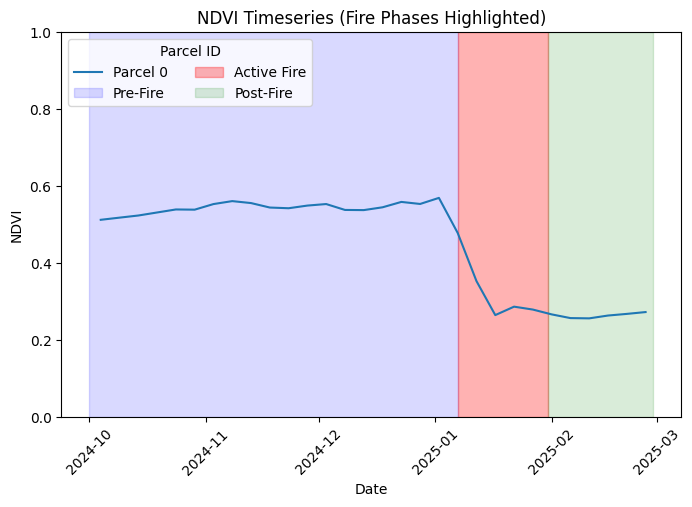

Plot saved at: experiments/pacific_palisades/plots/ndvi_fire_phases.png


In [7]:
from bin.plot_timeseries import plot_ndvi_timeseries

plot_ndvi_timeseries(ndvi_csv_path, experiment_path, TEMPORAL_EXTENT_PRE_FIRE, TEMPORAL_EXTENT_FIRE, TEMPORAL_EXTENT_POST_FIRE)

## Sentinel-5p

In [8]:
import os
import pandas as pd

# List of Sentinel-5P bands to process
s5p_bands = ["CO", "HCHO", "NO2", "O3", "SO2", "CH4"]  # You can add more bands as needed

# Define output path
results_dir = os.path.join(experiment_path, "s5p-results")
os.makedirs(results_dir, exist_ok=True)  # Ensure directory exists
s5p_output_csv = os.path.join(results_dir, "s5p_fire.csv")

# Skip processing if the file already exists
if os.path.exists(s5p_output_csv):
    print(f"Skipping execution: File already exists at {s5p_output_csv}")
else:
    print("Processing Sentinel-5P data...")

    # Dictionary to store DataFrames for each band
    band_dfs = {}

    # Function to process each band and convert to DataFrame
    def process_s5p_band(band_name):
        """Loads Sentinel-5P data for a specific band, aggregates, and returns a cleaned DataFrame."""
        print(f"Processing {band_name} data...")

        # Load Sentinel-5P L2 data for the band
        s5cube = connection.load_collection(
            "SENTINEL_5P_L2",
            temporal_extent=TEMPORAL_EXTENT,
            bands=[band_name]  # Load one band at a time
        )

        # Aggregate temporally (daily means)
        s5fire = s5cube.aggregate_temporal_period(reducer="mean", period="day")

        # Aggregate spatially (mean per parcel)
        s5fire = s5fire.aggregate_spatial(reducer="mean", geometries=fields)

        # Execute the processing graph and retrieve the result
        s5fire_result = s5fire.execute()

        # Convert dictionary to DataFrame
        df = pd.DataFrame(s5fire_result.items(), columns=["date", band_name])

        # Convert date column to datetime format
        df["date"] = pd.to_datetime(df["date"])

        # Flatten nested lists and extract the first value
        df[band_name] = df[band_name].apply(
            lambda x: x[0][0] if isinstance(x, list) and x and isinstance(x[0], list) and x[0] else None
        )

        # Convert None to NaN and ensure numeric values
        df[band_name] = pd.to_numeric(df[band_name], errors="coerce")

        return df

    # Process all bands and store DataFrames in a dictionary
    for band in s5p_bands:
        band_dfs[band] = process_s5p_band(band)

    # Merge all DataFrames on the "date" column
    s5p_combined_df = pd.DataFrame({"date": band_dfs[s5p_bands[0]]["date"]})  # Start with one band
    for band in s5p_bands:
        s5p_combined_df = pd.merge(s5p_combined_df, band_dfs[band], on="date", how="outer")

    # Save merged results as CSV
    s5p_combined_df.to_csv(s5p_output_csv, index=False)
    print(f"S5P fire data {s5p_bands} saved at: {s5p_output_csv}")


Processing Sentinel-5P data...
Processing CO data...
Processing HCHO data...
Processing NO2 data...
Processing O3 data...
Processing SO2 data...
Processing CH4 data...
S5P fire data ['CO', 'HCHO', 'NO2', 'O3', 'SO2', 'CH4'] saved at: experiments/pacific_palisades/s5p-results/s5p_fire.csv


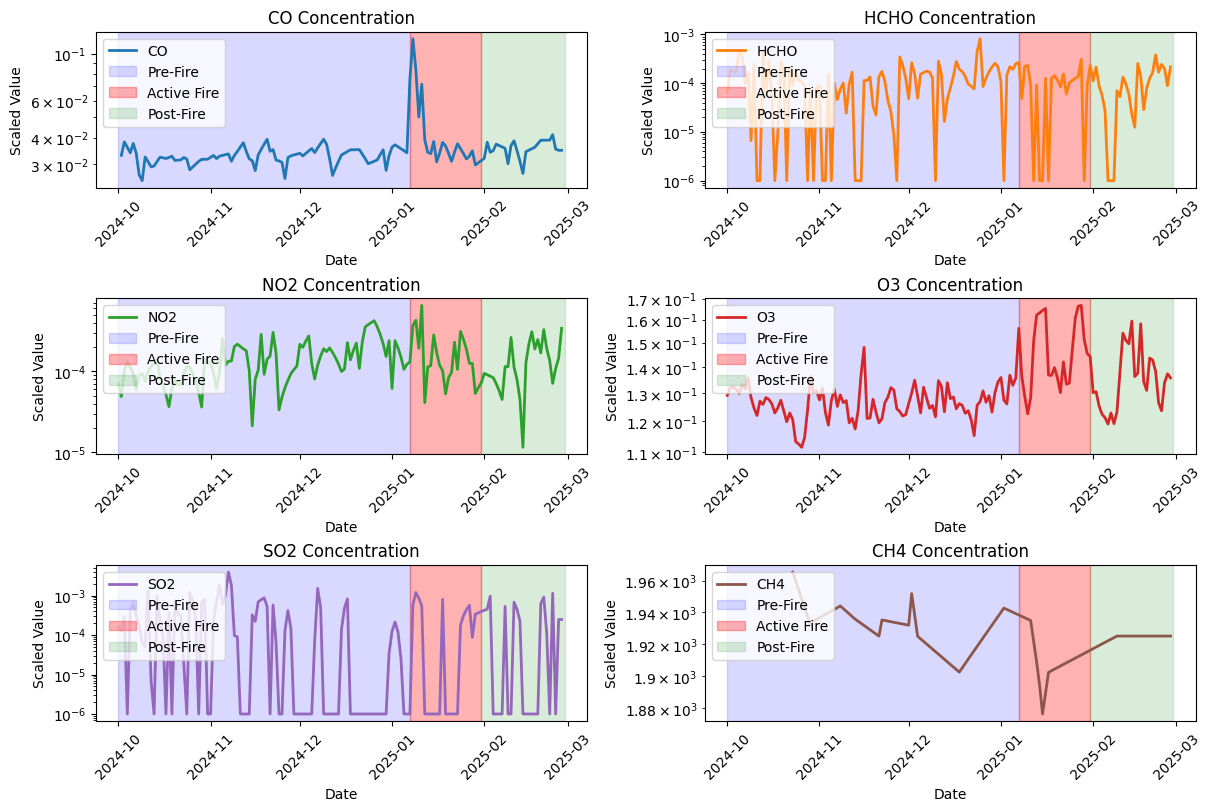

Plot saved at: experiments/pacific_palisades/plots/s5p_fire_phases.png


In [9]:
from bin.plot_timeseries import plot_s5p_timeseries

plot_s5p_timeseries(s5p_csv_path, experiment_path, TEMPORAL_EXTENT_PRE_FIRE, TEMPORAL_EXTENT_FIRE, TEMPORAL_EXTENT_POST_FIRE)

## Merging

In [11]:
# Convert date ranges to datetime (force them to be timezone-naive)
pre_fire_start, pre_fire_end = map(lambda d: pd.to_datetime(d).tz_localize(None), TEMPORAL_EXTENT_PRE_FIRE)
fire_start, fire_end = map(lambda d: pd.to_datetime(d).tz_localize(None), TEMPORAL_EXTENT_FIRE)
post_fire_start, post_fire_end = map(lambda d: pd.to_datetime(d).tz_localize(None), TEMPORAL_EXTENT_POST_FIRE)

# Define results directory
results_dir = os.path.join(experiment_path, "merged-results")
os.makedirs(results_dir, exist_ok=True)

# Load NDVI data
ndvi_df = pd.read_csv(ndvi_csv_path)
ndvi_df.rename(columns={"band_unnamed": "ndvi"}, inplace=True)

# Load Sentinel-5P data
s5p_df = pd.read_csv(s5p_csv_path)

# Convert date columns to datetime and ensure they are timezone-naive
ndvi_df["date"] = pd.to_datetime(ndvi_df["date"]).dt.tz_localize(None)
s5p_df["date"] = pd.to_datetime(s5p_df["date"]).dt.tz_localize(None)

# Merge NDVI and S5P DataFrames on the "date" column (Outer Join to keep all records)
merged_df = pd.merge(ndvi_df, s5p_df, on="date", how="outer")

# Assign phase labels
def categorize_phase(date):
    if pd.isnull(date):  # Handle NaT cases
        return None
    if pre_fire_start <= date < pre_fire_end:
        return "pre"
    elif fire_start <= date <= fire_end:
        return "active"
    elif post_fire_start < date <= post_fire_end:
        return "post"
    return None  # If outside all defined ranges

merged_df["phase"] = merged_df["date"].apply(categorize_phase)

# Save merged DataFrame as CSV
merged_csv_path = os.path.join(results_dir, "merged_timeseries.csv")
merged_df.to_csv(merged_csv_path, index=False)

print(f"Merged timeseries saved at: {merged_csv_path}")

merged_df

Merged timeseries saved at: experiments/pacific_palisades/merged-results/merged_timeseries.csv


,date,feature_index,ndvi,CO,HCHO,NO2,O3,SO2,CH4,phase
0,2024-09-30,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None
1,2024-10-01,NaN,NaN,NaN,0.000065,0.000071,0.129199,0.000158,NaN,pre
2,2024-10-02,NaN,NaN,0.033073,0.000191,0.000049,0.132006,0.000129,NaN,pre
3,2024-10-03,NaN,NaN,0.038286,0.000172,0.000102,0.132279,0.000295,NaN,pre
4,2024-10-04,0.0,0.512399,NaN,0.000170,0.000131,0.131550,-0.001080,NaN,pre
...,...,...,...,...,...,...,...,...,...,...
146,2025-02-23,NaN,NaN,0.039009,0.000167,0.000136,0.126650,-0.000693,NaN,post
147,2025-02-24,NaN,NaN,0.041395,0.000242,0.000071,0.123703,0.001138,NaN,post
148,2025-02-25,NaN,NaN,0.035377,0.000199,0.000109,0.133902,-0.000219,NaN,post
149,2025-02-26,0.0,0.272753,0.034939,0.000089,0.000146,0.137364,0.000248,NaN,post
